Dataset loaded successfully!
Dataset shape: (185013, 9)

First five records:
   Customer ID Customer Status Date Order was placed Delivery Date   Order ID  \
0          579          Silver             01-Jan-17     07-Jan-17  123002578   
1         7574          SILVER             01-Jan-17     05-Jan-17  123004074   
2        28861            Gold             01-Jan-17     04-Jan-17  123000871   
3        43796            Gold             01-Jan-17     06-Jan-17  123002851   
4        54673            Gold             01-Jan-17     04-Jan-17  123003607   

     Product ID  Quantity Ordered  Total Retail Price for This Order  \
0  220101400106                 2                               92.6   
1  210201000009                 1                               21.7   
2  230100500068                 1                                1.7   
3  220100100633                 1                               47.9   
4  220200200043                 1                               36.9   

   

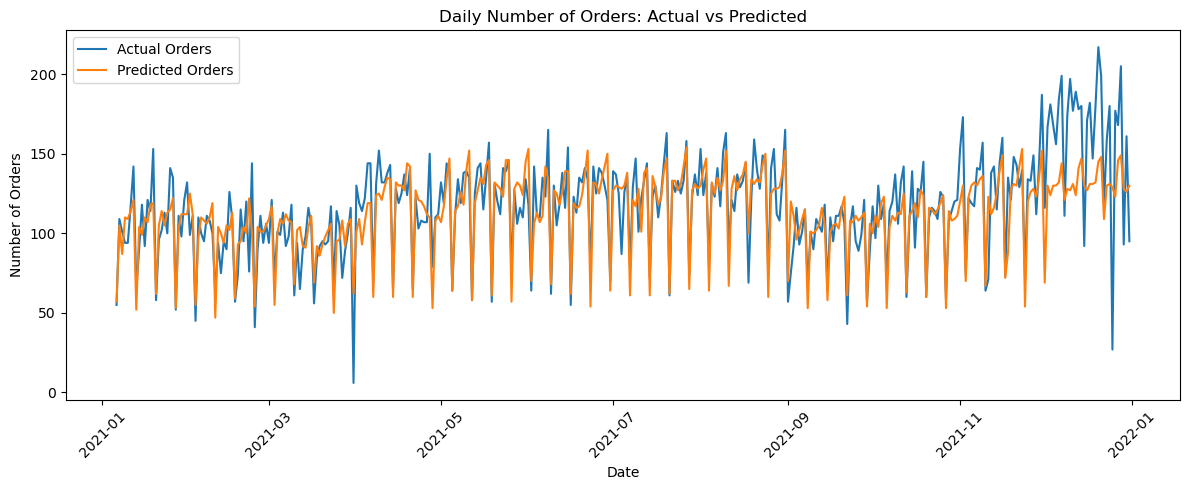


Feature Importance:
lag_7              0.614158
average_7_days     0.167721
lag_14             0.054113
lag_1              0.045742
average_30_days    0.035729
day_of_week        0.034769
day                0.024039
month              0.016520
year               0.005919
is_weekend         0.001290
dtype: float64


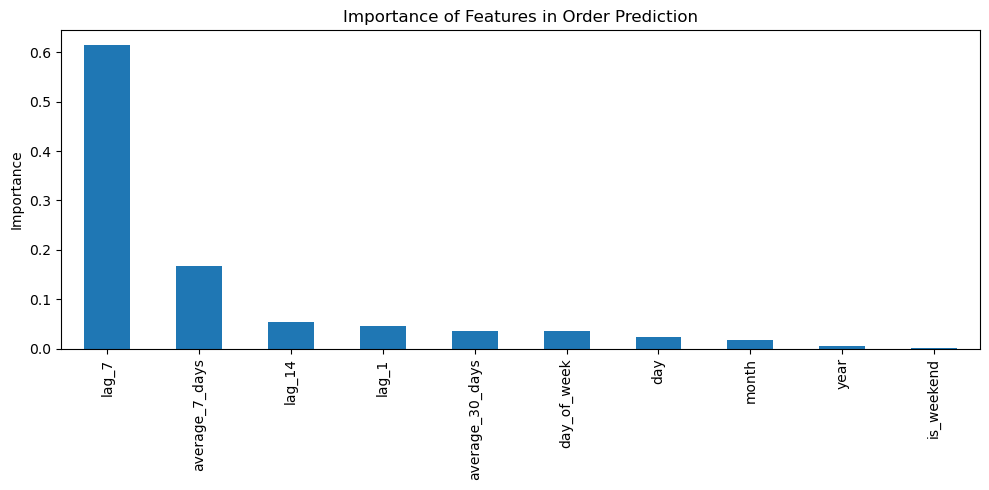

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("orders.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five records:")
print(df.head())

df["Date Order was placed"] = pd.to_datetime(
    df["Date Order was placed"],
    format="%d-%b-%y",
    errors="coerce"
)

df = df.dropna(subset=["Date Order was placed"])

daily_orders = (
    df.groupby("Date Order was placed")["Order ID"]
    .nunique()
    .sort_index()
)

daily_orders = daily_orders.asfreq("D", fill_value=0)
daily_orders.name = "Number_of_Orders"

print("\nDaily order counts:")
print(daily_orders.head())

def create_features(order_counts):
    data = pd.DataFrame(index=order_counts.index)

    data["day"] = data.index.day
    data["month"] = data.index.month
    data["year"] = data.index.year
    data["day_of_week"] = data.index.dayofweek
    data["is_weekend"] = (
        data.index.dayofweek >= 5
    ).astype(int)

    data["lag_1"] = order_counts.shift(1)
    data["lag_7"] = order_counts.shift(7)
    data["lag_14"] = order_counts.shift(14)

    data["average_7_days"] = (
        order_counts.shift(1).rolling(7).mean()
    )

    data["average_30_days"] = (
        order_counts.shift(1).rolling(30).mean()
    )

    return data

features = create_features(daily_orders)

dataset = features.copy()
dataset["target"] = daily_orders

dataset = dataset.dropna()

X = dataset.drop(columns=["target"])
y = dataset["target"]

print("\nFeatures used:")
print(list(X.columns))


split_point = int(len(dataset) * 0.80)

X_train = X.iloc[:split_point]
X_test = X.iloc[split_point:]

y_train = y.iloc[:split_point]
y_test = y.iloc[split_point:]

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("\nModel training completed!")


predictions = model.predict(X_test)
predictions = np.maximum(0, np.rint(predictions))

mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

print("\n----- MODEL EVALUATION -----")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")

results = pd.DataFrame({
    "Actual Orders": y_test,
    "Predicted Orders": predictions.astype(int)
})

print("\nActual vs Predicted Orders:")
print(results.head(15))

results.to_csv("order_predictions.csv", index=True)
print("\nPredictions saved to order_predictions.csv")

last_date = daily_orders.index[-1]
next_date = last_date + pd.Timedelta(days=1)

history = daily_orders.copy()

next_features = pd.DataFrame(
    index=pd.DatetimeIndex([next_date])
)

next_features["day"] = next_date.day
next_features["month"] = next_date.month
next_features["year"] = next_date.year
next_features["day_of_week"] = next_date.dayofweek
next_features["is_weekend"] = int(next_date.dayofweek >= 5)

next_features["lag_1"] = history.iloc[-1]
next_features["lag_7"] = history.iloc[-7]
next_features["lag_14"] = history.iloc[-14]

next_features["average_7_days"] = history.iloc[-7:].mean()
next_features["average_30_days"] = history.iloc[-30:].mean()

next_prediction = model.predict(next_features[X.columns])[0]

next_prediction = max(0, int(round(next_prediction)))

print("\n----- NEXT DAY PREDICTION -----")
print("Prediction date:", next_date.strftime("%d-%m-%Y"))
print("Expected number of orders:", next_prediction)

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Orders"
)

plt.plot(
    y_test.index,
    predictions,
    label="Predicted Orders"
)

plt.xlabel("Date")
plt.ylabel("Number of Orders")
plt.title("Daily Number of Orders: Actual vs Predicted")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)

importance.plot(kind="bar", figsize=(10, 5))
plt.title("Importance of Features in Order Prediction")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()
